# Loan Default Risk Prediction (Colab Mini Project)
**Goal:** predict whether a loan applicant is a *bad credit risk* using the German Credit dataset (OpenML `credit-g`).

**Pipeline:** data -> EDA -> model comparison (cross-validation) -> evaluation beyond accuracy -> threshold tuning -> save model -> REST API (Flask, runs inside Colab) -> automated tests.

> Educational demonstration only; not for real lending decisions.

Run the cells top to bottom (Runtime -> Run all).

## 1. Setup and data

In [ ]:
import json, threading, warnings
import joblib, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, precision_recall_fscore_support)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

data = fetch_openml("credit-g", version=1, as_frame=True)
df = data.frame.copy()
df["target"] = (df["class"] == "bad").astype(int)   # 1 = bad credit risk
X = df.drop(columns=["class", "target"])
y = df["target"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
X[cat_cols] = X[cat_cols].astype(object)

print("Rows, columns:", X.shape)
print("Numeric:", len(num_cols), "| Categorical:", len(cat_cols))
df.head()

Rows, columns: (1000, 20)
Numeric: 7 | Categorical: 13


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class,target
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,67,none,own,2,skilled,1,yes,yes,good,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,22,none,own,1,skilled,1,none,yes,bad,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,49,none,own,1,unskilled resident,2,none,yes,good,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,45,none,for free,1,skilled,2,none,yes,good,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,53,none,for free,2,skilled,2,none,yes,bad,1


## 2. Exploratory analysis (class imbalance matters)

target
good    700
bad     300
Name: count, dtype: int64 

target
good    0.7
bad     0.3
Name: count, dtype: float64


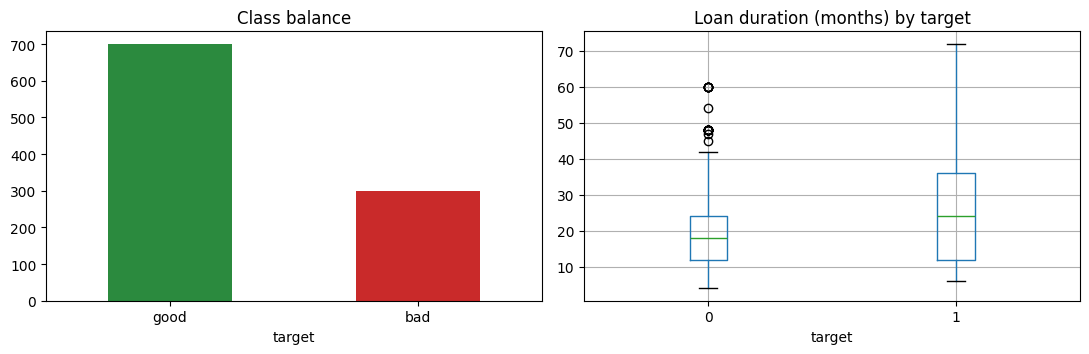

In [ ]:
counts = y.value_counts().rename({0: "good", 1: "bad"})
print(counts, "\n")
print((counts / len(y)).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
counts.plot.bar(ax=ax[0], color=["#2b8a3e", "#c92a2a"], rot=0, title="Class balance")
df.boxplot(column="duration", by="target", ax=ax[1])
ax[1].set_title("Loan duration (months) by target"); plt.suptitle("")
plt.tight_layout(); plt.show()

## 3. Train/test split and model comparison

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, clf in models.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)])
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k.replace("test_", ""): v.mean() for k, v in res.items() if k.startswith("test_")}})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.696,0.497,0.671,0.570,0.769
RandomForest,0.758,0.689,0.342,0.456,0.791


## 4. Fit the best model and evaluate on the held-out test set

Selected model: LogisticRegression
              precision    recall  f1-score   support

        good       0.89      0.73      0.80       140
         bad       0.56      0.80      0.66        60

    accuracy                           0.75       200
   macro avg       0.73      0.76      0.73       200
weighted avg       0.79      0.75      0.76       200

ROC-AUC: 0.806


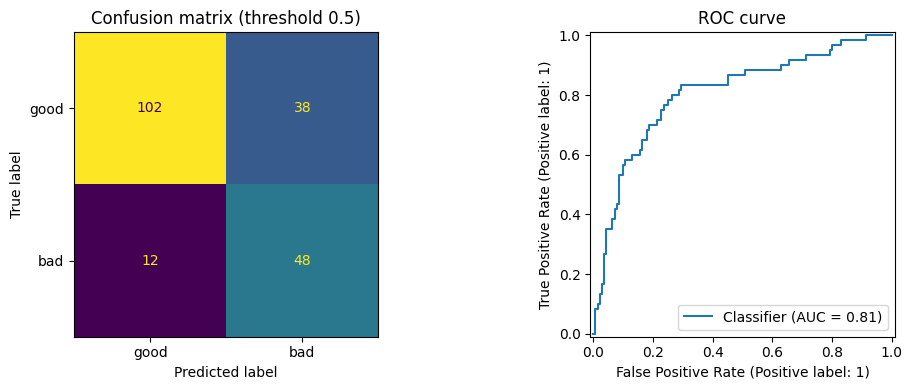

In [ ]:
best_name = cv_table["f1"].idxmax()
print("Selected model:", best_name)
pipe = Pipeline([("pre", pre), ("clf", models[best_name])]).fit(X_train, y_train)

proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["good", "bad"]))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["good", "bad"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (threshold 0.5)")
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1]); ax[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

## 5. Threshold tuning
A bank usually cares more about **catching bad loans (recall)** than raw accuracy. We choose the threshold using cross-validated predictions on the *training* data only, then check it once on the test set.

In [ ]:
cv_proba = cross_val_predict(Pipeline([("pre", pre), ("clf", models[best_name])]),
                             X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.arange(0.2, 0.81, 0.05)
rows = []
for t in thresholds:
    p, r, f, _ = precision_recall_fscore_support(y_train, (cv_proba >= t).astype(int),
                                                 average="binary", zero_division=0)
    rows.append({"threshold": round(t, 2), "precision": p, "recall": r, "f1": f})
th = pd.DataFrame(rows).set_index("threshold").round(3)
print(th)
BEST_T = float(th["f1"].idxmax())
print("\nChosen threshold:", BEST_T)

pred_t = (proba >= BEST_T).astype(int)
print(classification_report(y_test, pred_t, target_names=["good", "bad"]))

           precision  recall     f1
threshold                          
0.20           0.391   0.929  0.551
0.25           0.413   0.908  0.568
0.30           0.434   0.867  0.579
0.35           0.444   0.812  0.574
0.40           0.471   0.779  0.587
0.45           0.481   0.729  0.579
0.50           0.495   0.671  0.570
0.55           0.515   0.625  0.565
0.60           0.537   0.571  0.554
0.65           0.553   0.500  0.525
0.70           0.576   0.442  0.500
0.75           0.603   0.367  0.456
0.80           0.676   0.288  0.404

Chosen threshold: 0.4
              precision    recall  f1-score   support

        good       0.90      0.62      0.73       140
         bad       0.49      0.83      0.61        60

    accuracy                           0.69       200
   macro avg       0.69      0.73      0.67       200
weighted avg       0.77      0.69      0.70       200



## 6. Save the model

In [ ]:
defaults = {c: (float(X_train[c].median()) if c in num_cols else X_train[c].mode()[0]) for c in X.columns}
bundle = {"pipeline": pipe, "columns": X.columns.tolist(), "defaults": defaults,
          "threshold": BEST_T, "model_name": best_name}
joblib.dump(bundle, "loan_risk_model.joblib")
print("Saved loan_risk_model.joblib")

Saved loan_risk_model.joblib


## 7. REST API (Flask running inside Colab)

In [ ]:
from flask import Flask, jsonify, request
from werkzeug.serving import make_server
import threading
import joblib
import pandas as pd

api = Flask(__name__)
B = joblib.load("loan_risk_model.joblib")

@api.get("/api/health")
def health():
    return jsonify({"status": "ok", "model": B["model_name"], "threshold": B["threshold"]})

@api.post("/api/predict")
def predict():
    record = request.get_json(silent=True)
    if not isinstance(record, dict):
        return jsonify({"error": "Send a JSON object of feature names and values."}), 400
    unknown = [k for k in record if k not in B["columns"]]
    if unknown:
        return jsonify({"error": f"Unknown fields: {unknown}"}), 400
    row = {**B["defaults"], **{k: v for k, v in record.items() if v not in (None, "")}}
    try:
        frame = pd.DataFrame([row], columns=B["columns"])
        p = float(B["pipeline"].predict_proba(frame)[0][1])
    except Exception:
        return jsonify({"error": "Could not process the supplied values."}), 400
    return jsonify({"prediction": "bad" if p >= B["threshold"] else "good",
                    "default_probability": round(p, 4),
                    "notice": "Educational demonstration only."})

# Shut down the existing server if it is already running in this session
if "server" in globals():
    try:
        server.shutdown()
        print("Stopped existing background server.")
    except Exception:
        pass

# start the server in a background thread
server = make_server("127.0.0.1", 5000, api)
threading.Thread(target=server.serve_forever, daemon=True).start()
print("API running on http://127.0.0.1:5000")

Stopped existing background server.
API running on http://127.0.0.1:5000


In [ ]:
print(requests.get("http://127.0.0.1:5000/api/health").json())

sample = json.loads(X_test.iloc[[0]].to_json(orient="records"))[0]
print("Actual label:", "bad" if y_test.iloc[0] else "good")
print(requests.post("http://127.0.0.1:5000/api/predict", json=sample).json())

# partial input works because missing fields use training defaults
print(requests.post("http://127.0.0.1:5000/api/predict", json={"duration": 48, "credit_amount": 12000}).json())

# bad input returns 400
r = requests.post("http://127.0.0.1:5000/api/predict", json=[1, 2])
print(r.status_code, r.json())

INFO:werkzeug:127.0.0.1 - - [21/Oct/2026 07:27:17] "GET /api/health HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [21/Oct/2026 07:27:17] "POST /api/predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [21/Oct/2026 07:27:17] "POST /api/predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [21/Oct/2026 07:27:17] "POST /api/predict HTTP/1.1" 400 -


{'model': 'LogisticRegression', 'status': 'ok', 'threshold': 0.4}
Actual label: good
{'default_probability': 0.4066, 'notice': 'Educational demonstration only.', 'prediction': 'bad'}
{'default_probability': 0.6434, 'notice': 'Educational demonstration only.', 'prediction': 'bad'}
400 {'error': 'Send a JSON object of feature names and values.'}


## 8. Automated tests

In [ ]:
def run_tests():
    c = api.test_client()
    assert c.get("/api/health").status_code == 200
    ok = c.post("/api/predict", json=sample)
    assert ok.status_code == 200
    body = ok.get_json()
    assert body["prediction"] in ("good", "bad") and 0 <= body["default_probability"] <= 1
    assert c.post("/api/predict", json=[1, 2]).status_code == 400
    assert c.post("/api/predict", json={"not_a_field": 1}).status_code == 400
    assert c.post("/api/predict", data="not json").status_code == 400
    print("All 5 API tests passed")
run_tests()

All 5 API tests passed


## 9. Summary for your report
- **Problem:** binary classification of loan applicants (good vs bad credit risk), 1000 rows, 30% positive class.
- **Why not accuracy alone:** a model that always says "good" gets about 70% accuracy but catches no bad loans, so we report precision, recall, F1, ROC-AUC and the confusion matrix.
- **Method:** preprocessing pipeline (imputation, scaling, one-hot), two models compared with 5-fold stratified CV, class weights for imbalance, threshold chosen on training CV data.
- **Deployment:** saved with joblib and served through a Flask REST API with input validation and tests.
- **Limitations:** small dataset, historical bias possible, not suitable for real lending decisions.

**Possible extensions:** SHAP feature importance, a Gradio UI, hyperparameter search, fairness check across age groups.